# 05 — What Do Customers Complain About? (Portuguese review text)

**CRISP-DM phases:** Data Understanding → Modeling (text)

**Questions**
1. Can the review **text** tell good from bad reviews, and which words matter most?
2. What are the main complaint themes in bad reviews?
3. **Hypothesis from Phase 4:** do bad reviews on multi-seller orders complain about **missing items** (split shipments)?
4. Do topics found *without rules* (NMF) agree with our themes?

**Approach:** TF-IDF + logistic regression trained on the review scores we already have, instead of a large pre-trained transformer. It is light (a few MB), fast, explainable (we can read the word weights) and easy to deploy in the dashboard. Text helpers are in `src/text.py`.

In [1]:
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from text import STOPWORDS, THEMES, normalize, tag_themes

# sklearn warns that our stopword list contains words its tokenizer splits differently;
# harmless here, so we hide it to keep the notebook readable.
warnings.filterwarnings("ignore", message=".*stop_words may be inconsistent.*")

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

GREY, RED, BLUE, DARK, GREEN, SAND = "#B0B7BF", "#D1495B", "#2E86AB", "#2B2D42", "#81B29A", "#F2CC8F"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.titlelocation": "left",
    "font.size": 10,
})


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


orders = pd.read_parquet(DATA_DIR / "orders.parquet")
reviews = orders.dropna(subset=["review_score"]).copy()
reviews["has_comment"] = reviews["review_comment"].fillna("").str.strip().str.len() > 0

comments = reviews[reviews["has_comment"]].copy()
comments["text"] = comments["review_comment"].map(normalize)
comments["bad"] = comments["is_bad_review"].astype(int)

print(f"Reviews: {len(reviews):,} | with a comment: {len(comments):,} ({reviews['has_comment'].mean():.0%})")
print(f"Bad-review rate — commented: {comments['bad'].mean():.1%}, all reviews: {reviews['is_bad_review'].mean():.1%}")
print("\nExample of normalisation:")
print(" raw:       ", comments["review_comment"].iloc[3])
print(" normalized:", comments["text"].iloc[3])

Reviews: 95,824 | with a comment: 38,872 (41%)
Bad-review rate — commented: 23.8%, all reviews: 12.8%

Example of normalisation:
 raw:        Na descrição do produto quando fui efetuar a compra, estava detalhado os pentes de disfarce.
Quando recebe o produto verifiquei e notei que não havia os pentes 0.5 e 1.5
 normalized: na descricao do produto quando fui efetuar a compra estava detalhado os pentes de disfarce quando recebe o produto verifiquei e notei que nao havia os pentes 0 5 e 1 5


In [2]:
# Unhappy customers write more: share of reviews with a comment, by score
by_score = reviews.groupby("review_score")["has_comment"].mean()
by_score.index = by_score.index.astype(int)
by_score.to_frame("share_with_comment").round(3).T

review_score,1,2,3,4,5
share_with_comment,0.776,0.679,0.433,0.312,0.358


## 1. Text classifier: is this a bad review?

- **TF-IDF** turns each comment into numbers: a word gets a high weight when it is frequent in *this* comment but rare overall, so generic words like "produto" count little. We use single words and pairs of words (*bigrams*), so "nao recebi" is a feature on its own.
- **Logistic regression** learns one weight per word/bigram: positive weights push towards "bad review".
- Same **time-based split** as Phase 4 (train before Mar 2018, validate Mar–Apr, test May–Aug).

In [3]:
train = comments[comments["purchase_ts"] < "2018-03-01"]
valid = comments[(comments["purchase_ts"] >= "2018-03-01") & (comments["purchase_ts"] < "2018-05-01")]
test = comments[comments["purchase_ts"] >= "2018-05-01"]


def text_model(C):
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.9,
                                  stop_words=STOPWORDS, sublinear_tf=True)),
        ("clf", LogisticRegression(C=C, class_weight="balanced", max_iter=2000)),
    ])


# C controls regularisation: small C = simpler model (smaller weights)
tuning = []
for C in [0.3, 1, 3, 10]:
    m = text_model(C).fit(train["text"], train["bad"])
    tuning.append({"C": C, "valid PR-AUC": average_precision_score(valid["bad"], m.predict_proba(valid["text"])[:, 1])})
tuning = pd.DataFrame(tuning)
best_C = tuning.loc[tuning["valid PR-AUC"].idxmax(), "C"]

model = text_model(best_C).fit(train["text"], train["bad"])
proba = model.predict_proba(test["text"])[:, 1]
print(f"Best C = {best_C}")
print(f"Test PR-AUC: {average_precision_score(test['bad'], proba):.3f} (random = {test['bad'].mean():.3f})")
print(f"Test ROC-AUC: {roc_auc_score(test['bad'], proba):.3f}")
tuning.round(3)

Best C = 3.0
Test PR-AUC: 0.797 (random = 0.202)
Test ROC-AUC: 0.951


,C,valid PR-AUC
0,0.3,0.857
1,1.0,0.869
2,3.0,0.872
3,10.0,0.871


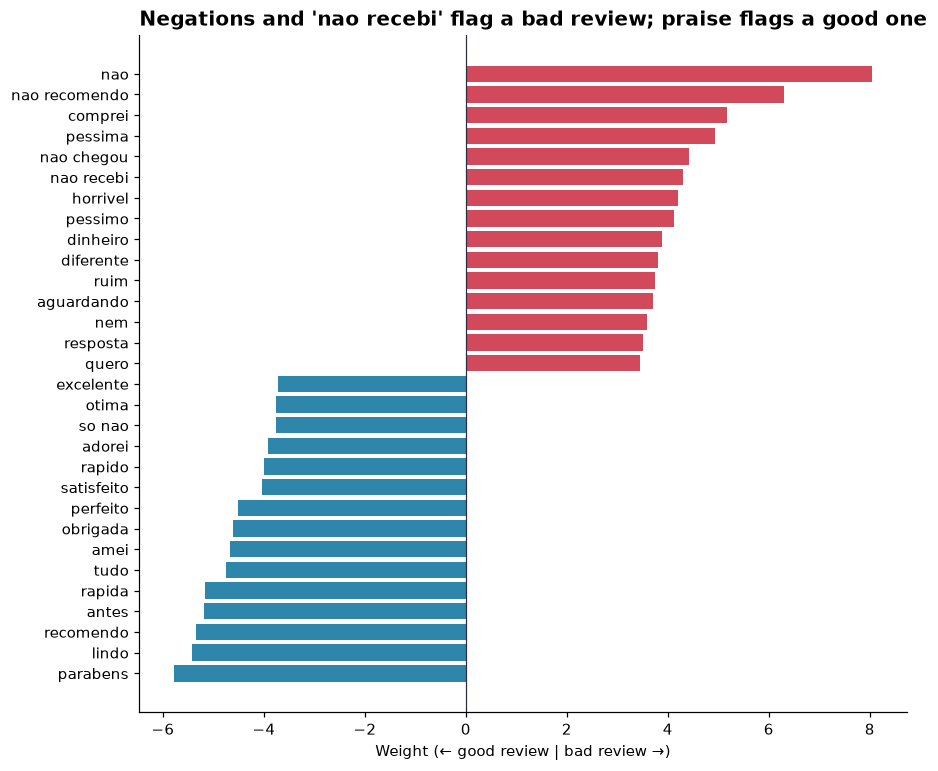

In [4]:
vocab = model.named_steps["tfidf"].get_feature_names_out()
coef = model.named_steps["clf"].coef_[0]
weights = pd.Series(coef, index=vocab).sort_values()
top = pd.concat([weights.head(15), weights.tail(15)])

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top.index, top.values, color=[BLUE if v < 0 else RED for v in top.values])
ax.axvline(0, color=DARK, lw=0.8)
ax.set_xlabel("Weight (← good review | bad review →)")
ax.set_title("Negations and 'nao recebi' flag a bad review; praise flags a good one")
save(fig, "17_text_model_words")
plt.show()

In [5]:
# Try it on new sentences (written for this test, not from the data)
examples = [
    "Chegou rápido e bem embalado, recomendo!",
    "Produto bom, mas demorou muito para chegar.",
    "Não recebi o produto até agora.",
    "Veio só um dos itens, o outro não chegou.",
    "Produto veio quebrado, quero a devolução do dinheiro.",
    "Ótima qualidade, superou minhas expectativas.",
]
pd.DataFrame({
    "comment": examples,
    "bad_review_probability": model.predict_proba([normalize(e) for e in examples])[:, 1].round(2),
})

,comment,bad_review_probability
0,"Chegou rápido e bem embalado, recomendo!",0.01
1,"Produto bom, mas demorou muito para chegar.",0.19
2,Não recebi o produto até agora.,0.98
3,"Veio só um dos itens, o outro não chegou.",0.99
4,"Produto veio quebrado, quero a devolução do di...",0.99
5,"Ótima qualidade, superou minhas expectativas.",0.05


## 2. Complaint themes in bad reviews

Themes are regular expressions (see `src/text.py`) written after reading real comments. A comment can belong to several themes. They are measured **only on bad reviews**, because a keyword is not a complaint by itself ("dentro do prazo" is praise).

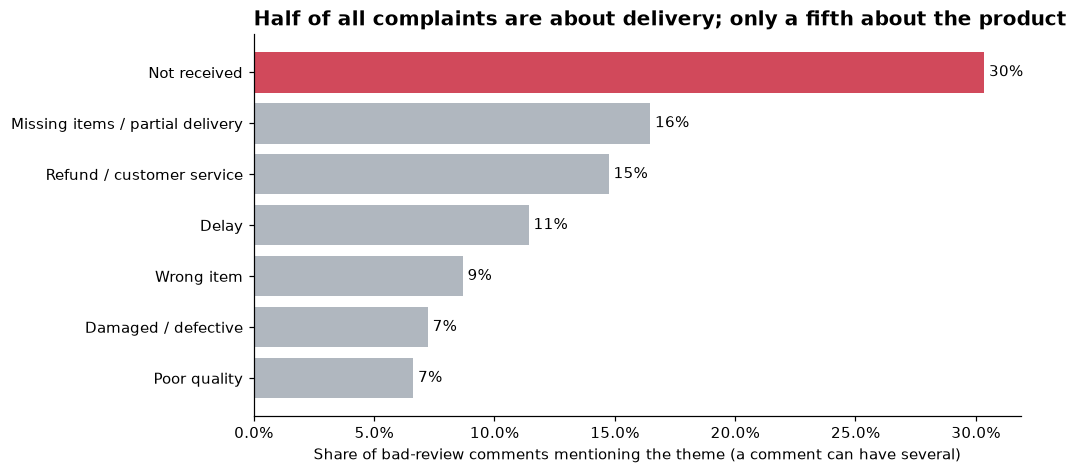

Bad-review comments about DELIVERY (any of ['Not received', 'Missing items / partial delivery', 'Delay']): 50.5%
Bad-review comments about the PRODUCT (any of ['Damaged / defective', 'Wrong item', 'Poor quality']): 20.8%
Bad-review comments with no theme: 29%


,bad reviews,good reviews
Missing items / partial delivery,0.165,0.028
Not received,0.304,0.034
Delay,0.114,0.038
Damaged / defective,0.072,0.014
Wrong item,0.087,0.012
Poor quality,0.066,0.011
Refund / customer service,0.148,0.033


In [6]:
themes = tag_themes(comments["text"])
bad_mask = comments["bad"] == 1

theme_share = themes[bad_mask].mean().sort_values()
no_theme = (~themes[bad_mask].any(axis=1)).mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(theme_share.index, theme_share.values,
               color=[RED if v == theme_share.max() else GREY for v in theme_share.values])
ax.bar_label(bars, labels=[f"{v:.0%}" for v in theme_share.values], padding=3)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Share of bad-review comments mentioning the theme (a comment can have several)")
ax.set_title("Half of all complaints are about delivery; only a fifth about the product")
save(fig, "18_complaint_themes")
plt.show()

delivery_themes = ["Not received", "Missing items / partial delivery", "Delay"]
product_themes = ["Damaged / defective", "Wrong item", "Poor quality"]
print(f"Bad-review comments about DELIVERY (any of {delivery_themes}): "
      f"{themes.loc[bad_mask, delivery_themes].any(axis=1).mean():.1%}")
print(f"Bad-review comments about the PRODUCT (any of {product_themes}): "
      f"{themes.loc[bad_mask, product_themes].any(axis=1).mean():.1%}")
print(f"Bad-review comments with no theme: {no_theme:.0%}")
pd.DataFrame({"bad reviews": themes[bad_mask].mean(), "good reviews": themes[~bad_mask].mean()}).round(3)

## 3. Testing the hypotheses

**H1 (from Phase 4):** bad reviews on **multi-seller** orders complain about **missing items** more than bad reviews on single-seller orders.

**H2 (sanity check):** bad reviews on **late** orders talk about **delay / not received** more than bad reviews on on-time orders. If this fails, our themes are not measuring what we think.

In [7]:
bad_comments = comments[bad_mask].join(themes[bad_mask])
bad_comments["seller_group"] = np.where(bad_comments["n_sellers"] >= 2, "2+ sellers", "1 seller")
bad_comments["delivery"] = np.where(bad_comments["is_late"], "Late", "On time")


def theme_test(group_col, theme):
    table = pd.crosstab(bad_comments[group_col], bad_comments[theme])
    _, p, _, _ = stats.chi2_contingency(table)
    return bad_comments.groupby(group_col)[theme].mean(), p


h1, p1 = theme_test("seller_group", "Missing items / partial delivery")
h2a, p2a = theme_test("delivery", "Delay")
h2b, p2b = theme_test("delivery", "Not received")

fmt_p = lambda p: "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
print("H1 — 'Missing items' in bad reviews:", h1.round(3).to_dict(), fmt_p(p1))
print("H2 — 'Delay' in bad reviews:", h2a.round(3).to_dict(), fmt_p(p2a))
print("H2 — 'Not received' in bad reviews:", h2b.round(3).to_dict(), fmt_p(p2b))
print("\nBad-review comments per group:", bad_comments["seller_group"].value_counts().to_dict())

H1 — 'Missing items' in bad reviews: {'1 seller': 0.141, '2+ sellers': 0.577} p < 0.001
H2 — 'Delay' in bad reviews: {'Late': 0.204, 'On time': 0.076} p < 0.001
H2 — 'Not received' in bad reviews: {'Late': 0.554, 'On time': 0.197} p < 0.001

Bad-review comments per group: {'1 seller': 8728, '2+ sellers': 506}


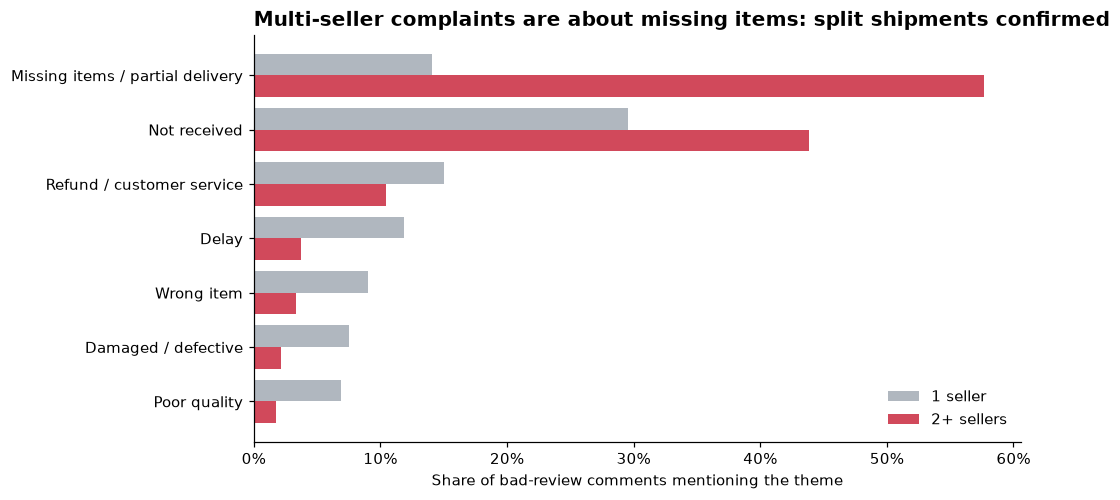

In [8]:
by_seller_theme = bad_comments.groupby("seller_group")[list(THEMES)].mean().T.sort_values("2+ sellers")

fig, ax = plt.subplots(figsize=(9, 4.8))
y = np.arange(len(by_seller_theme))
ax.barh(y + 0.2, by_seller_theme["1 seller"], height=0.4, color=GREY, label="1 seller")
ax.barh(y - 0.2, by_seller_theme["2+ sellers"], height=0.4, color=RED, label="2+ sellers")
ax.set_yticks(y, by_seller_theme.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Share of bad-review comments mentioning the theme")
ax.set_title("Multi-seller complaints are about missing items: split shipments confirmed")
ax.legend(frameon=False, loc="lower right")
save(fig, "19_themes_by_seller_count")
plt.show()

## 4. Topics found without rules (NMF)

**NMF (non-negative matrix factorisation)** breaks the TF-IDF matrix of bad comments into a few *topics*, each a weighted list of words. Nobody tells it what the topics are, so if they match our hand-written themes, the themes are credible. It can also reveal themes we missed.

In [9]:
nmf_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=10, max_df=0.5, stop_words=STOPWORDS, sublinear_tf=True)
X_bad = nmf_vec.fit_transform(bad_comments["text"])
nmf = NMF(n_components=8, random_state=42, max_iter=500).fit(X_bad)

terms = nmf_vec.get_feature_names_out()
topics = pd.DataFrame({
    f"Topic {i + 1}": [terms[j] for j in comp.argsort()[::-1][:10]]
    for i, comp in enumerate(nmf.components_)
}).T
topics["share_of_comments"] = np.bincount(nmf.transform(X_bad).argmax(axis=1), minlength=8) / X_bad.shape[0]
topics.round(3)

,0,1,2,3,4,5,6,7,8,9,share_of_comments
Topic 1,nao recebi,recebi,recebi produto,produto,momento,momento nao,agora,agora nao,hoje,produto errado,0.098
Topic 2,entregue,nao entregue,produto nao,produto,produto entregue,entregue produto,entregue prazo,momento,produto ainda,entregue nao,0.065
Topic 3,ainda,ainda nao,produto ainda,nao recebi,aguardando,ainda aguardando,avaliar,recebi ainda,nao chegou,nao entregue,0.071
Topic 4,chegou,nao chegou,produto nao,produto,produto chegou,chegou ainda,produto ainda,so chegou,agora,chegou produto,0.065
Topic 5,comprei,so,dois,recebi,apenas,so recebi,produtos,comprei dois,duas,recebi apenas,0.220
Topic 6,veio,produto veio,produto,defeito,veio defeito,nao veio,errado,veio errado,pedi,faltando,0.141
Topic 7,entrega,prazo,prazo entrega,demora,demora entrega,dia,atraso,entrega produto,dias,agora,0.153
Topic 8,qualidade,gostei,produto,pessima,nao gostei,pessima qualidade,recomendo,nao recomendo,produto pessima,loja,0.187


## 5. Save artefacts for the dashboard

In [10]:
joblib.dump(model, MODEL_DIR / "review_text_model.joblib")

theme_out = comments[["order_id", "purchase_ts", "review_score", "bad", "n_sellers", "is_late",
                      "customer_state", "category"]].join(themes)
theme_out.to_parquet(DATA_DIR / "review_themes.parquet", index=False)
weights.rename("weight").rename_axis("term").reset_index().to_parquet(DATA_DIR / "text_model_weights.parquet", index=False)
print(f"Saved text model, {len(theme_out):,} tagged comments and word weights")

Saved text model, 38,872 tagged comments and word weights


## Key findings

1. **The text tells good from bad reviews very well.** The TF-IDF + logistic regression model reaches PR-AUC **0.80** (random = 0.20) and ROC-AUC **0.95** on the unseen test months. It can triage incoming comments automatically.
2. **The words make sense.** Negations (*nao, nem, nao recomendo*), *nao recebi / nao chegou*, *pessima, horrivel* and *dinheiro* point to bad reviews; *parabens, lindo, recomendo, rapida, antes* point to good ones. A nice nuance: *"so nao"* points to a **good** review ("só não dou 5 estrelas porque…").
3. **Unhappy customers write more:** 78% of 1-star reviews have a comment vs 36% of 5-star reviews.
4. **Half of all complaints are about delivery, only a fifth about the product.** Among bad-review comments, **50.5%** mention a delivery theme (not received, missing items, delay) vs **20.8%** a product theme (damaged, wrong item, poor quality). The single biggest theme is **"not received" (30%)** — on orders that the system marks as *delivered*.
5. **Delivered… but not received.** Even among bad reviews on orders delivered **on time**, **20%** say the order was not received. This points to a delivery-confirmation problem (wrong address, parcel left elsewhere, or "delivered" status set too early).
6. **Hypothesis H1 confirmed — split shipments.** In bad reviews on **multi-seller** orders, **58%** complain about missing items vs **14%** on single-seller orders (p < 0.001). This explains the Phase 4 finding (47% bad reviews on multi-seller orders even when on time).
7. **Sanity check H2 passed.** Bad reviews on late orders mention delay (20% vs 8%) and "not received" (55% vs 20%) far more than on-time ones (p < 0.001), so the themes measure what we intended.
8. **NMF agrees with the rules.** Without any rules, NMF finds topics for *not received / still waiting* (4 topics, ~30% of comments), *bought two, received only one* (22%), *came defective / wrong / missing* (14%), *delivery time / delay* (15%) and *poor quality / do not recommend* (19%).

**Business recommendations**
- **Proof of delivery:** require photo or signature confirmation, and audit carriers with many "delivered but not received" complaints.
- **Split shipments:** tell customers upfront when an order ships in several parcels, track each parcel, and mark the order as delivered only when every parcel arrives.
- **Automatic triage:** run the text model on new comments to route "not received" and "missing item" complaints to a priority queue.